<a href="https://colab.research.google.com/github/Gunnny/dream-atlas/blob/main/notebooks/01_explore_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install datasets

In [10]:
from datasets import load_dataset
ds = load_dataset("DReAMy-lib/DreamBank-dreams-en")
print(ds)

README.md:   0%|          | 0.00/2.45k [00:00<?, ?B/s]

data/train-00000-of-00001-24937aef854be1(…): reconstructing file:   0%|          |  0.00B / 12.0MB            

data/train-00000-of-00001-24937aef854be1(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/22415 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['series', 'description', 'dreams', 'gender', 'year'],
        num_rows: 22415
    })
})


In [11]:
import pandas as pd

df = ds["train"].to_pandas()
df["word_count"] = df["dreams"].str.split().str.len()

df_clean = df[df["word_count"] >= 5].copy()
print(len(df), "→", len(df_clean))

print("vorher:", len(df_clean))
df_clean = df_clean.drop_duplicates(subset="dreams").reset_index(drop=True)
print("nachher:", len(df_clean))

df_clean.to_parquet("dreams_clean.parquet")

22415 → 22347
vorher: 22347
nachher: 22096


Nur Berichte mit unter 5 Wörtern entfernt (68 Zeilen, 0,3 %) – das sind Titel ohne Text. Kurze Berichte ab 5 Wörtern sind inhaltlich vollständig und bleiben erhalten; gefiltert wird später pro Anwendungsfall über word_count.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = vectorizer.fit_transform(df_clean["dreams"])
print(X.shape)

zellen = X.shape[0] * X.shape[1]
print("Zellen insgesamt:", zellen)
print("davon besetzt:   ", X.nnz)
print("Füllgrad:        ", round(100 * X.nnz / zellen, 3), "%")
print("Speicher:        ", round(X.data.nbytes / 1e6, 1), "MB")
print("wäre dicht:      ", round(zellen * 8 / 1e9, 2), "GB")

(22096, 24011)
Zellen insgesamt: 530547056
davon besetzt:    1170708
Füllgrad:         0.221 %
Speicher:         9.4 MB
wäre dicht:       4.24 GB


In [13]:
import numpy as np

def search(query, k=5):
    q = vectorizer.transform([query])
    sims = (X @ q.T).toarray().ravel()
    top = np.argsort(-sims)[:k]

    for i in top:
        print(round(float(sims[i]), 3), "|", df_clean["dreams"].iloc[i][:200])
        print("---")


0.415 | Nightmare. I wake up frightened. I was being chased.
---
0.391 | I was being chased by two people. It was a man and a woman. They chased me into a house where a stranger was sitting at a desk trying to make a computer run on old batteries. I went to find some and w
---
0.371 | It was a dream similar to the one on the 6th of September; the same familiar characters (schoolmates) and others I have never seen or I don't remember. My dream was still centered around the girl I lo
---
0.349 | Another dream I had was that I was being chased by government agents because they had done certain things that I was against.
---
0.325 | I and several other people -- I don't believe I knew any of these people in particular, but they were all about my age ---were being chased by this group of other people, some of them older people, so
---
0.295 | Through The Bowling Alley  I'm at Carter School. I'm leading a group of younger kids. We're being pursued. We get out of the school through the bowlin

In [22]:
search("I was being chased through a dark house")
search("I was being pursued through a dark house")
search("Ich wurde durch ein dunkles Haus verfolgt")

0.415 | Nightmare. I wake up frightened. I was being chased.
---
0.391 | I was being chased by two people. It was a man and a woman. They chased me into a house where a stranger was sitting at a desk trying to make a computer run on old batteries. I went to find some and w
---
0.371 | It was a dream similar to the one on the 6th of September; the same familiar characters (schoolmates) and others I have never seen or I don't remember. My dream was still centered around the girl I lo
---
0.349 | Another dream I had was that I was being chased by government agents because they had done certain things that I was against.
---
0.325 | I and several other people -- I don't believe I knew any of these people in particular, but they were all about my age ---were being chased by this group of other people, some of them older people, so
---
0.295 | Through The Bowling Alley  I'm at Carter School. I'm leading a group of younger kids. We're being pursued. We get out of the school through the bowlin

Baseline TF-IDF. Lexikalische Suche funktioniert bei wörtlicher Übereinstimmung (bester Treffer 0,413). Beim Synonym „pursued“ statt „chased“ fällt der beste Wert auf 0,293, und die inhaltlich passenden Treffer aus der ersten Anfrage erscheinen gar nicht mehr. Bei deutscher Anfrage versagt das Verfahren vollständig (Höchstwert 0,27, Treffer rein zufällig über Ländernamen). Grund: TF-IDF vergleicht Zeichenketten, keine Bedeutung.

In [14]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "keine GPU")

True
Tesla T4


In [15]:
!pip install -q sentence-transformers


In [16]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
print(model.get_sentence_embedding_dimension())


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

384


/tmp/ipykernel_402/850366859.py:4: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(model.get_sentence_embedding_dimension())


Batches:   0%|          | 0/346 [00:00<?, ?it/s]

(22096, 384)


In [17]:
texte = df_clean["dreams"].tolist()

E = model.encode(
    texte,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,
)
print(E.shape)

Batches:   0%|          | 0/346 [00:00<?, ?it/s]

(22096, 384)


In [18]:
print(len(df_clean), X.shape[0], E.shape[0])

22096 22096 22096


In [25]:
def search_emb(query, k=5, min_words=20):
    q = model.encode([query], normalize_embeddings=True)
    sims = (E @ q.T).ravel()

    maske = df_clean["word_count"].to_numpy() >= min_words
    sims = np.where(maske, sims, -1)

    top = np.argsort(-sims)[:k]
    for i in top:
        print(round(float(sims[i]), 3), "|", df_clean["dreams"].iloc[i][:200])
        print("---")

In [26]:
search_emb("I was being chased through a dark house")
search_emb("I was being pursued through a dark house")
search_emb("Ich wurde durch ein dunkles Haus verfolgt")

0.675 | Someone is trying to kill me. I was in my house and it actually looked like my house did about 7or 8 years ago. In the dream I wake up, realized there were people trying to break into my house. I ran 
---
0.668 | I was at the door of a dark room. I heard someone inside the room call me in. I was afraid and I backed away. But then I felt a hand pulling me inside, and a feeling of panic and terror came over me. 
---
0.667 | I think it was nighttime. I went into a hallway. The door at the end of the hall was closed. I thought I saw a shadow through the crack at the bottom of the door. I hesitated but decided to open it ju
---
0.665 | I ran all the way home, facing traffic, along a busy street lined with trees, dodging in and out among the trunks and branches, pretending I was catching passes, evading tacklers, etc.  My neighborhoo
---
0.66 | I was walking home down a country road at dusk when an unknown man began chasing me. I was terrified and ran furiously toward my home. I mana

In [29]:
queries = [
    # --- Sprachpaare: inhaltlich identisch, DE/EN ---
    {"id": "zaehne_de", "lang": "de", "topic": "teeth",
     "text": "Meine Zähne fielen mir einer nach dem anderen aus und ich konnte nichts dagegen tun"},
    {"id": "zaehne_en", "lang": "en", "topic": "teeth",
     "text": "My teeth were falling out one by one and I could not stop it"},

    {"id": "fliegen_de", "lang": "de", "topic": "flying",
     "text": "Ich konnte fliegen und bin über die Dächer der Stadt geschwebt"},
    {"id": "fliegen_en", "lang": "en", "topic": "flying",
     "text": "I could fly and floated over the rooftops of the city"},

    {"id": "spaet_de", "lang": "de", "topic": "late",
     "text": "Ich kam zu spät zu einer wichtigen Prüfung und konnte den Raum nicht finden"},
    {"id": "spaet_en", "lang": "en", "topic": "late",
     "text": "I was late for an important exam and could not find the room"},

    # --- Deutsch ---
    {"id": "entfuehrung", "lang": "de", "topic": "kidnapping",
     "text": "Zwei Männer wollten mich entführen und in ein Auto zerren"},
    {"id": "schwimmen", "lang": "de", "topic": "swimming",
     "text": "Ich bin in einem See geschwommen und kam nicht mehr ans Ufer zurück"},
    {"id": "klauen", "lang": "de", "topic": "stealing",
     "text": "Ich habe in einem Laden etwas gestohlen und hatte Angst, erwischt zu werden"},
    {"id": "messer", "lang": "de", "topic": "knife",
     "text": "Ein fremder Mann stand vor mir und bedrohte mich mit einem Messer"},

    # --- Englisch ---
    {"id": "tod", "lang": "en", "topic": "death",
     "text": "My grandmother who died years ago was alive again and talking to me"},
    {"id": "liebe", "lang": "en", "topic": "love",
     "text": "I was in love with someone and we were happy together"},
    {"id": "suche", "lang": "en", "topic": "searching",
     "text": "I was looking for something but I could not remember what it was"},
    {"id": "militaer", "lang": "en", "topic": "military",
     "text": "I was a soldier in a war and there was shooting all around me"},
    {"id": "drogen", "lang": "en", "topic": "drugs",
     "text": "I had taken some kind of drug and everything around me felt strange"},
    {"id": "sex", "lang": "en", "topic": "sex",
     "text": "I was in bed being intimate with someone I knew"},
    {"id": "verfolgung", "lang": "en", "topic": "chase",
     "text": "I was being chased through a dark house"},

    # --- Härtefälle: vermutlich nicht im Korpus ---
    {"id": "gaming", "lang": "en", "topic": "gaming",
     "text": "I was playing a video game and could not stop playing"},
    {"id": "drachen", "lang": "en", "topic": "dragons",
     "text": "A dragon was flying over a castle and breathing fire"},
    {"id": "mathe", "lang": "de", "topic": "math",
     "text": "Ich musste an der Tafel eine schwierige Matheaufgabe lösen"},
]

print(len(queries))


20


In [30]:
def retrieve_tfidf(query, k=5):
    q = vectorizer.transform([query])
    sims = (X @ q.T).toarray().ravel()
    return np.argsort(-sims)[:k]

def retrieve_emb(query, k=5, min_words=0):
    q = model.encode([query], normalize_embeddings=True)
    sims = (E @ q.T).ravel()
    if min_words > 0:
        maske = df_clean["word_count"].to_numpy() >= min_words
        sims = np.where(maske, sims, -1)
    return np.argsort(-sims)[:k]

In [31]:
from collections import defaultdict

methoden = ["tfidf", "emb", "emb20"]
runs = {}
pool = defaultdict(set)

for qu in queries:
    runs[(qu["id"], "tfidf")] = list(retrieve_tfidf(qu["text"]))
    runs[(qu["id"], "emb")]   = list(retrieve_emb(qu["text"], min_words=0))
    runs[(qu["id"], "emb20")] = list(retrieve_emb(qu["text"], min_words=20))

    for m in methoden:
        pool[qu["id"]].update(runs[(qu["id"], m)])

print("Paare zu bewerten:", sum(len(v) for v in pool.values()))

Paare zu bewerten: 213


In [32]:
rows = []
for qu in queries:
    for idx in sorted(pool[qu["id"]]):
        rows.append({
            "query_id": qu["id"],
            "query":    qu["text"],
            "doc_idx":  int(idx),
            "dream":    df_clean["dreams"].iloc[idx],
            "relevant": "",
        })

judge = (pd.DataFrame(rows)
         .sample(frac=1, random_state=42)
         .sort_values("query_id", kind="stable")
         .reset_index(drop=True))

judge.to_csv("judgements.csv", index=False)
print(len(judge))

213


**Relevant** = 1, wenn das zentrale Ereignis der Anfrage im Traum tatsächlich vorkommt.

**Nicht relevant** = 0, wenn nur die Stimmung oder das Umfeld passt.

**Beispiel**: Anfrage „verfolgt werden“. Ein Traum über Flucht vor einem Mann → 1. Ein Traum über ein dunkles Haus ohne Verfolgung → 0.

In [35]:
gold = pd.read_csv("judgements_final.csv")
lookup = {(r.query_id, r.doc_idx): r.relevant for r in gold.itertuples()}

ergebnis = {}
for m in methoden:
    p = [sum(lookup.get((qu["id"], int(i)), 0) for i in runs[(qu["id"], m)]) / 5
         for qu in queries]
    ergebnis[m] = sum(p) / len(p)

for m, v in ergebnis.items():
    print(f"{m:8s} P@5 = {v:.3f}")

tfidf    P@5 = 0.360
emb      P@5 = 0.560
emb20    P@5 = 0.580


In [36]:
for qu in queries:
    a = sum(lookup.get((qu["id"], int(i)), 0) for i in runs[(qu["id"], "emb")]) / 5
    b = sum(lookup.get((qu["id"], int(i)), 0) for i in runs[(qu["id"], "emb20")]) / 5
    if a != b:
        print(f'{qu["id"]:12s} emb={a:.1f}  emb20={b:.1f}')

fliegen_de   emb=0.6  emb20=0.8
schwimmen    emb=0.2  emb20=0.6
klauen       emb=0.4  emb20=0.6
tod          emb=0.4  emb20=0.2
militaer     emb=0.4  emb20=0.2
sex          emb=0.4  emb20=0.2
gaming       emb=0.4  emb20=0.2
drachen      emb=0.6  emb20=0.8
mathe        emb=0.4  emb20=0.6


In [37]:
for lang in ["de", "en"]:
    ids = [qu["id"] for qu in queries if qu["lang"] == lang]
    p = [sum(lookup.get((qid, int(i)), 0) for i in runs[(qid, "emb")]) / 5 for qid in ids]
    print(lang, len(ids), round(sum(p)/len(p), 3))

de 8 0.55
en 12 0.567


In [38]:
paare = [("zaehne_de", "zaehne_en"),
         ("fliegen_de", "fliegen_en"),
         ("spaet_de", "spaet_en")]

for de, en in paare:
    a = sum(lookup.get((de, int(i)), 0) for i in runs[(de, "emb")]) / 5
    b = sum(lookup.get((en, int(i)), 0) for i in runs[(en, "emb")]) / 5
    print(f"{de:12s} {a:.1f}    {en:12s} {b:.1f}")

zaehne_de    1.0    zaehne_en    1.0
fliegen_de   0.6    fliegen_en   0.8
spaet_de     0.8    spaet_en     0.2


In [39]:
for de, en in paare:
    s_de = set(int(i) for i in runs[(de, "emb")])
    s_en = set(int(i) for i in runs[(en, "emb")])
    print(f"{de:12s} gemeinsame Treffer: {len(s_de & s_en)} von 5")

zaehne_de    gemeinsame Treffer: 3 von 5
fliegen_de   gemeinsame Treffer: 4 von 5
spaet_de     gemeinsame Treffer: 0 von 5


In [40]:
for i in runs[("spaet_en", "emb")]:
    print(df_clean["dreams"].iloc[int(i)][:120])
    print("---")

The main setting was an unfamiliar hotel room. I vaguely remember my father walking around there, paying very little att
---
I am at some resort hotel or something, a conference. I am tired and want to lay down for a nap in my room before going 
---
Anne Co from SVH and Lucy from the TV show ER were there. The three of us were working together. We were supposed to be 
---
It was the beginning of a new semester at my alma mater, and I had moved into a dorm, on the side facing the quad.  The 
---
It is a large room. There are pictures around on the walls like a real student room from my Leiden days.
---


In [41]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=0)
XY = pca.fit_transform(E)

print(XY.shape)
print("erklaerte Varianz:", pca.explained_variance_ratio_)
print("zusammen:", pca.explained_variance_ratio_.sum())

(22096, 2)
erklaerte Varianz: [0.05815846 0.03608195]
zusammen: 0.09424041


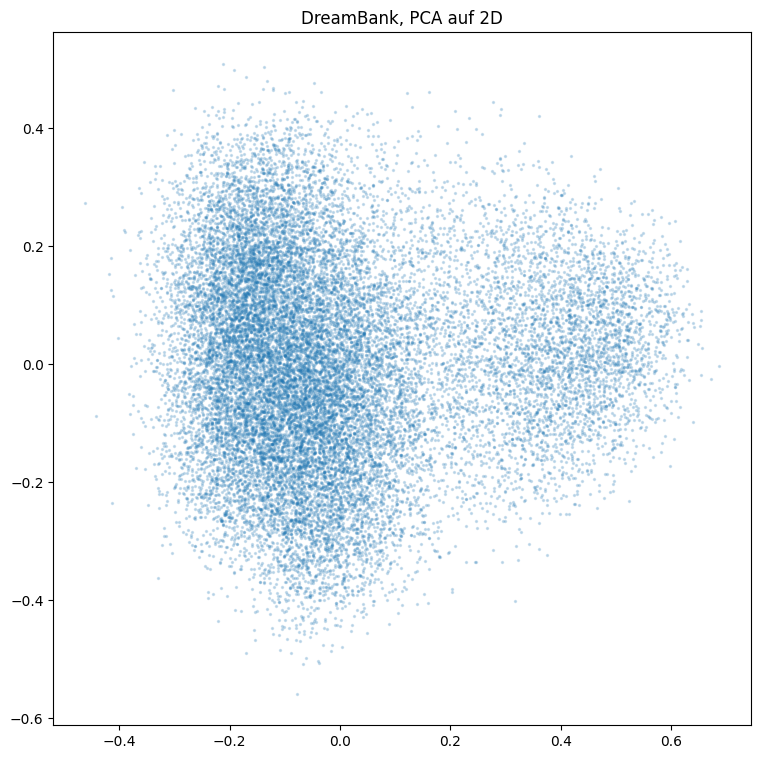

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 9))
plt.scatter(XY[:, 0], XY[:, 1], s=2, alpha=0.2)
plt.title("DreamBank, PCA auf 2D")
plt.show()

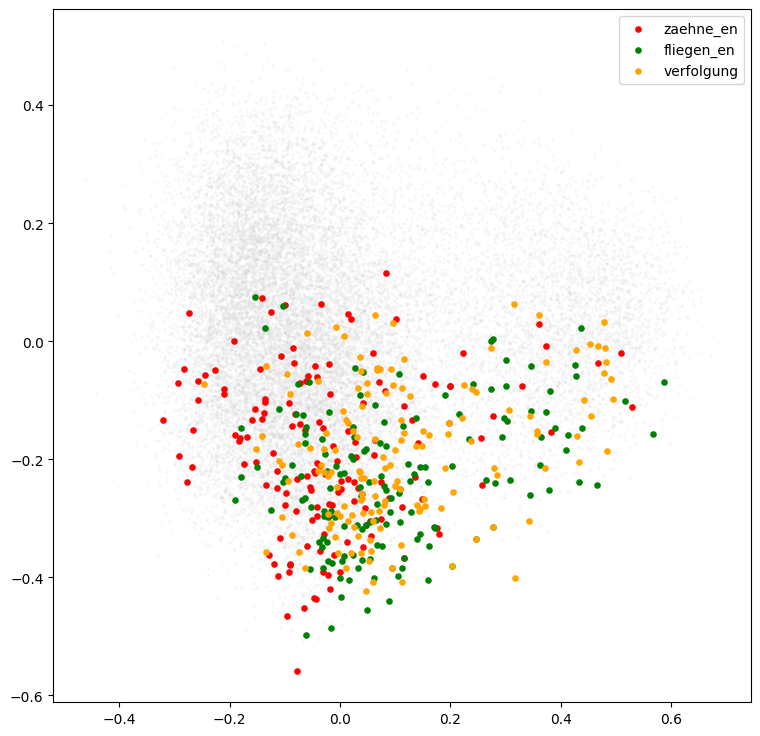

In [43]:
import numpy as np
import matplotlib.pyplot as plt

themen = ["zaehne_en", "fliegen_en", "verfolgung"]
farben = ["red", "green", "orange"]

plt.figure(figsize=(9, 9))
plt.scatter(XY[:, 0], XY[:, 1], s=2, alpha=0.1, color="lightgray")

for qid, farbe in zip(themen, farben):
    q = model.encode([next(x["text"] for x in queries if x["id"] == qid)],
                     normalize_embeddings=True)
    top = np.argsort(-(E @ q.T).ravel())[:150]
    plt.scatter(XY[top, 0], XY[top, 1], s=14, color=farbe, label=qid)

plt.legend()
plt.show()

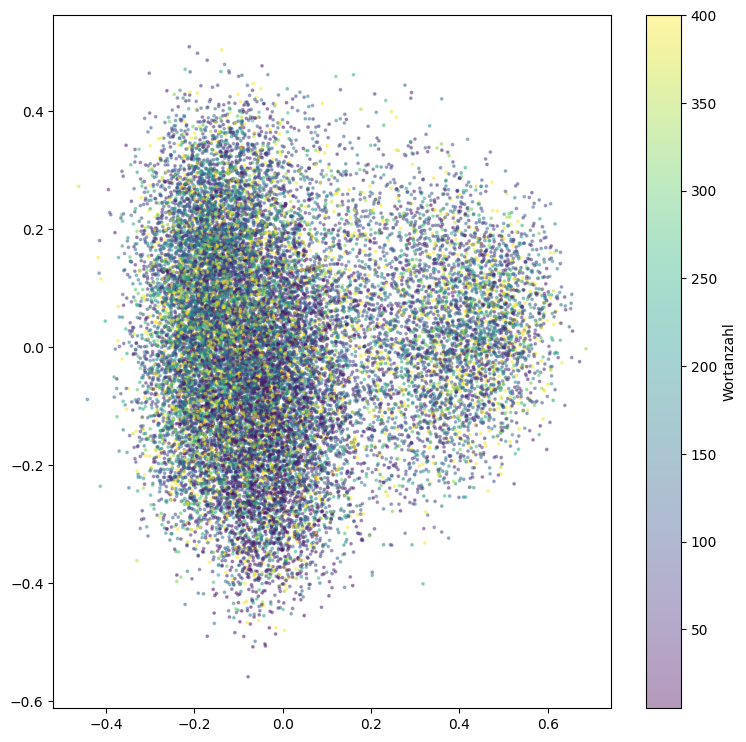

In [44]:
plt.figure(figsize=(9, 9))
s = plt.scatter(XY[:, 0], XY[:, 1], s=3, alpha=0.4,
                c=df_clean["word_count"].clip(upper=400), cmap="viridis")
plt.colorbar(s, label="Wortanzahl")
plt.show()

In [45]:
links  = np.argsort(XY[:, 0])[:5]
rechts = np.argsort(-XY[:, 0])[:5]

print("=== LINKS (PC1 niedrig) ===")
for i in links:
    print(df_clean["dreams"].iloc[i][:200], "\n---")

print("\n=== RECHTS (PC1 hoch) ===")
for i in rechts:
    print(df_clean["dreams"].iloc[i][:200], "\n---")

=== LINKS (PC1 niedrig) ===
I am a reporter. I am interviewing both of the president's wives. There are a lot of reporters there. The older, wiser wife does most of the talking. The young pretty one just smiles a lot. I try to g 
---
Ed Hemway has 2 shotguns, one of which he is loaning or giving me. The one turned over to me is complete and ready to shoot, whereas the one he keeps for himself is minus a stock. Every says he always 
---
I am given a task of teaching. I must prepare a series of questions and so on as I will moderate or facilitate a panel discussion on topics given me by my woman boss. It's a big job. I set to work rea 
---
(04/15/00)["Fixing up the office."] I am in my office, perhaps at a university. Sharon is working hard at fixing things up. More than I want, really. She wants to get permission from the authorities t 
---
We are to interview a "person of the cloth" for a class that I am taking. I decide to interview Pedro. It is winter. I drop my mittens in the snow a

In [48]:
rahmen = r"^\s*(?:I dreamed|I dreamt|Last night I|I had a dream|I have a dream)"
anteil = df_clean["dreams"].str.contains(rahmen, case=False, regex=True).mean()
print(f"{anteil:.1%} der Berichte beginnen mit einer Rahmenformel")

7.7% der Berichte beginnen mit einer Rahmenformel


In [49]:
import umap

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)
UV = reducer.fit_transform(E)
print(UV.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(22096, 2)


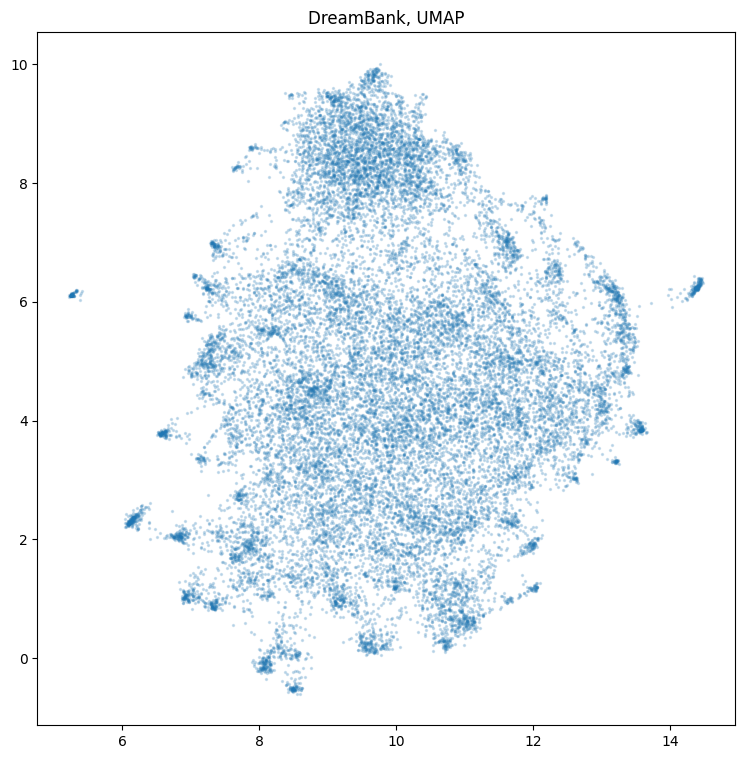

In [50]:
plt.figure(figsize=(9, 9))
plt.scatter(UV[:, 0], UV[:, 1], s=2, alpha=0.2)
plt.title("DreamBank, UMAP")
plt.show()

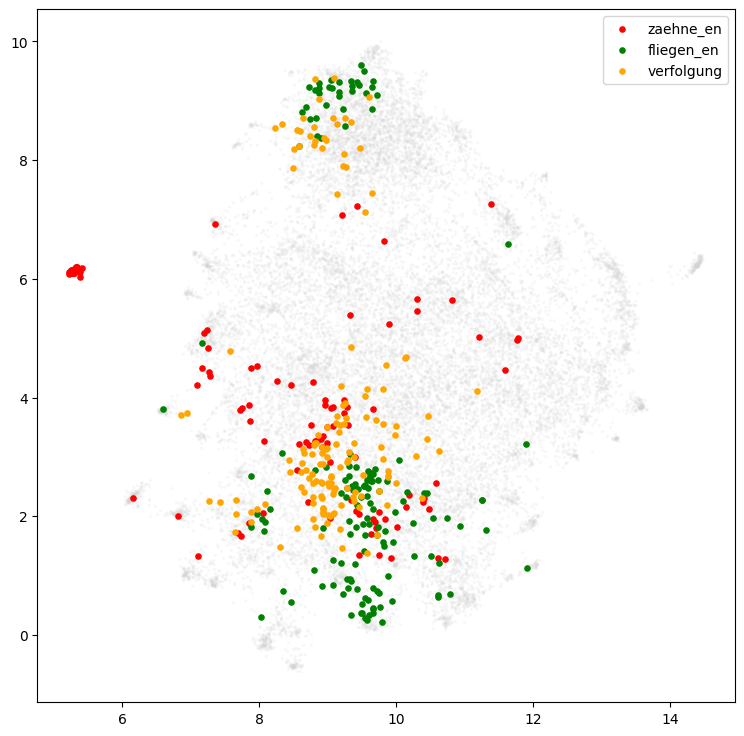

In [51]:
plt.figure(figsize=(9, 9))
plt.scatter(UV[:, 0], UV[:, 1], s=2, alpha=0.1, color="lightgray")

for qid, farbe in zip(themen, farben):
    q = model.encode([next(x["text"] for x in queries if x["id"] == qid)],
                     normalize_embeddings=True)
    top = np.argsort(-(E @ q.T).ravel())[:150]
    plt.scatter(UV[top, 0], UV[top, 1], s=14, color=farbe, label=qid)

plt.legend()
plt.show()

In [52]:
from sklearn.cluster import KMeans

k = 12
km = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = km.fit_predict(E)

In [53]:
terme = np.array(vectorizer.get_feature_names_out())

for c in range(k):
    maske = labels == c
    mittel = np.asarray(X[maske].mean(axis=0)).ravel()
    top = terme[np.argsort(-mittel)[:8]]
    print(f"{c:2d} ({maske.sum():5d} Träume): {', '.join(top)}")

 0 ( 1329 Träume): game, play, playing, like, people, ball, man, school
 1 ( 2209 Träume): man, say, says, like, feel, room, love, don
 2 ( 1824 Träume): said, store, like, went, man, mother, small, didn
 3 ( 1779 Träume): saw, man, like, came, said, house, gun, got
 4 ( 2118 Träume): woman, say, says, like, room, house, mary, don
 5 ( 1609 Träume): room, house, door, like, building, floor, people, went
 6 ( 2233 Träume): went, said, girl, came, room, didn, saw, mother
 7 ( 1673 Träume): car, driving, road, bus, going, street, like, way
 8 (  852 Träume): church, andrew, father, people, said, like, wedding, married
 9 ( 1047 Träume): water, boat, swimming, lake, fish, river, pool, ocean
10 ( 1697 Träume): working, said, class, office, work, people, like, room
11 ( 3726 Träume): dream, like, remember, dreamt, dreamed, going, just, went


In [54]:
import re

RAHMEN = re.compile(
    r"^\s*(?:"
    r"(?:last night|one night|the other night)?[,\s]*"
    r"i (?:dreamed|dreamt|had a dream|have a dream)"
    r"(?:\s+(?:once again|again|last night))?"
    r"(?:\s+(?:that|about|of|where|i was))?"
    r"|dreamt?\s+(?:of|that|about)"
    r"|(?:my|the)\s+(?:last\s+)?dream\s+(?:was|is)\s+(?:about|that)?"
    r"|another dream i had was(?:\s+that)?"
    r"|this is a dream[^.]*\."
    r"|all i remember is"
    r"|i can only (?:recall|remember)"
    r"|i don'?t remember[^,.]*[,.]"
    r")[\s,:]*",
    flags=re.IGNORECASE,
)

def entrahmen(text, max_runden=3):
    t = str(text)
    for _ in range(max_runden):
        neu = RAHMEN.sub("", t, count=1)
        if neu == t:
            break
        t = neu
    return t.strip()

df_clean["dreams_clean"] = df_clean["dreams"].apply(entrahmen)

geaendert = (df_clean["dreams_clean"] != df_clean["dreams"]).sum()
print(f"{geaendert} von {len(df_clean)} geändert ({geaendert/len(df_clean):.1%})")

1660 von 22096 geändert (7.5%)


In [55]:
geaend = df_clean[df_clean["dreams_clean"] != df_clean["dreams"]]
for _, r in geaend.sample(10, random_state=0).iterrows():
    print("VORHER :", " ".join(str(r["dreams"]).split()[:14]))
    print("NACHHER:", " ".join(str(r["dreams_clean"]).split()[:14]))
    print("---")

VORHER : I dreamt I was in the I---- office, quite as usual. I don't remember
NACHHER: in the I---- office, quite as usual. I don't remember what we were arguing
---
VORHER : Last night I had a dream that -- I can't remember anything that happened
NACHHER: -- I can't remember anything that happened before this -- I just remember that
---
VORHER : I dreamt last night that the kids were coming to town and we were
NACHHER: the kids were coming to town and we were going to go to the
---
VORHER : I dreamed I was in a large room, a waiting room of some sort.
NACHHER: in a large room, a waiting room of some sort. There were quite a
---
VORHER : I can only remember walking down a street late at night, and coming to
NACHHER: walking down a street late at night, and coming to a department store which
---
VORHER : I dreamed I was in the room of an old house which over looked
NACHHER: in the room of an old house which over looked a wide river. The
---
VORHER : I dreamed a cat irritated me, so I de

In [56]:
E2 = model.encode(
    df_clean["dreams_clean"].tolist(),
    batch_size=64, show_progress_bar=True, normalize_embeddings=True,
)
print(E2.shape)

Batches:   0%|          | 0/346 [00:00<?, ?it/s]

(22096, 384)


In [57]:
def retrieve_emb2(query, k=5):
    q = model.encode([query], normalize_embeddings=True)
    return np.argsort(-(E2 @ q.T).ravel())[:k]

p, unbewertet = [], 0
for qu in queries:
    treffer = retrieve_emb2(qu["text"])
    for i in treffer:
        if (qu["id"], int(i)) not in lookup:
            unbewertet += 1
    p.append(sum(lookup.get((qu["id"], int(i)), 0) for i in treffer) / 5)

print(f"P@5 neu: {sum(p)/len(p):.3f}  (alt: 0.560)")
print(f"unbewertete Treffer: {unbewertet} von 100")

P@5 neu: 0.530  (alt: 0.560)
unbewertete Treffer: 11 von 100


In [59]:
pca2 = PCA(n_components=2, random_state=0)
XY2 = pca2.fit_transform(E2)
print("erklärte Varianz:", pca2.explained_variance_ratio_.sum())

for seite, idx in [("NIEDRIG", np.argsort(XY2[:, 0])[:5]),
                   ("HOCH",    np.argsort(-XY2[:, 0])[:5])]:
    print(f"\n=== PC1 {seite} ===")
    for i in idx:
        print(" ", df_clean["dreams_clean"].iloc[i][:120])

erklärte Varianz: 0.08240062

=== PC1 NIEDRIG ===
  I am a reporter. I am interviewing both of the president's wives. There are a lot of reporters there. The older, wiser w
  Ed Hemway has 2 shotguns, one of which he is loaning or giving me. The one turned over to me is complete and ready to sh
  WALLY returns and he is very friendly, capable and practical; he is working for a family nearby whom we get to know; he 
  We are to interview a "person of the cloth" for a class that I am taking. I decide to interview Pedro. It is winter. I d
  I am given a task of teaching. I must prepare a series of questions and so on as I will moderate or facilitate a panel d

=== PC1 HOCH ===
  Last night I had a bizarre dream . First of all, this was after everybody left and after all the dust settled and I coul
  The dream took place in a place that was familiar to me but I couldn't tell what it was. All of the people in the dream 
  First I had some sort of sex dream or something. I can't remember mos

In [67]:
import re

LEER = (r"(?:a|an|the|some|some sort of|kind of|sort of|really|very|quite|"
        r"bizarre|odd|strange|weird|funny|vivid|long|short|good|bad|"
        r"nice|awful|terrible|crazy|wild|interesting|recurring)")

RAHMEN2 = re.compile(
    r"^\s*(?:"
    # "I dreamed that ..." / "Last night I dreamt ..."
    r"(?:last night|one night|the other night|first)?[,\s]*"
    r"i (?:dreamed|dreamt)\b(?:\s+(?:once again|again|last night))?"
    r"(?:\s+(?:that|about|of|where))?"
    # "I had a bizarre dream ..." - nur mit inhaltsleeren Fuellwoertern
    rf"|(?:last night|one night|the other night|first)?[,\s]*"
    rf"i had\s+(?:{LEER}\s+){{0,4}}dreams?\b"
    r"(?:\s+(?:that|about|where|in which))?"
    # "My dream was about ..." / "The dream took place ..."
    r"|(?:my|the)\s+(?:last\s+)?dream\b(?:\s+of\s+last\s+night)?\s*"
    r"(?:was|is|took place|could be called)(?:\s+(?:about|that))?"
    r"|another dream i had was(?:\s+that)?"
    r"|this is a dream[^.]*\."
    r"|all i remember is"
    r"|i can only (?:recall|remember)"
    r"|i don'?t remember[^,.]*[,.]"
    r")[\s,:]*",
    flags=re.IGNORECASE,
)

KOMPLEMENT = re.compile(r"\b(?:that|about|of|where|in which)[\s,:]*$", re.IGNORECASE)

def entrahmen2(text, max_runden=3):
    t = str(text).strip()
    for _ in range(max_runden):
        m = RAHMEN2.match(t)
        if not m:
            break
        if KOMPLEMENT.search(m.group(0)):
            t = t[m.end():].strip()          # Satz geht inhaltlich weiter
        else:
            punkt = t.find(".", m.start())   # ganzer Satz ist Verpackung
            t = (t[punkt + 1:] if punkt != -1 else "").strip()
    return t

In [68]:
tests = [
    "Last night I had a bizarre dream . First of all, this was after everybody left",
    "The dream took place in a place that was familiar to me but I couldn't tell",
    "First I had some sort of sex dream or something. I can't remember most of it.",
    "My dream of last night could be called a series of scenes. First I was in a big field",
    "I was dreaming inside my dream and it felt strange",   # darf NICHT verändert werden
]
for t in tests:
    print(RAHMEN2.sub("", t, count=1)[:70])

. First of all, this was after everybody left
in a place that was familiar to me but I couldn't tell
First I had some sort of sex dream or something. I can't remember most
a series of scenes. First I was in a big field
I was dreaming inside my dream and it felt strange


In [69]:
tests = [
    "I dreamed that I was walking through a dark house.",
    "Last night I had a bizarre dream . First of all, this was after everybody left",
    "The dream took place in a place that was familiar to me but I couldn't tell",
    "First I had some sort of sex dream or something. I can't remember most of it.",
    "My dream of last night could be called a series of scenes. First I was in a big field",
    "I was dreaming inside my dream and it felt strange",
]
for t in tests:
    print(repr(entrahmen2(t)[:70]))


'I was walking through a dark house.'
'First of all, this was after everybody left'
''
"First I had some sort of sex dream or something. I can't remember most"
'First I was in a big field'
'I was dreaming inside my dream and it felt strange'


In [70]:
df_clean["dreams_clean"] = df_clean["dreams"].apply(entrahmen2)

geaendert = (df_clean["dreams_clean"] != df_clean["dreams"]).sum()
leer = (df_clean["dreams_clean"].str.split().str.len() < 3).sum()
print(f"geändert: {geaendert} ({geaendert/len(df_clean):.1%})")
print(f"danach fast leer (<3 Wörter): {leer}")

for _, r in df_clean[df_clean["dreams_clean"] != df_clean["dreams"]] \
                .sample(10, random_state=1).iterrows():
    print("VORHER :", " ".join(str(r["dreams"]).split()[:16]))
    print("NACHHER:", " ".join(str(r["dreams_clean"]).split()[:16]))
    print("---")

geändert: 1728 (7.8%)
danach fast leer (<3 Wörter): 35
VORHER : I dreamed that I was sitting at a counter at the A. V. It was about
NACHHER: I was sitting at a counter at the A. V. It was about 1:30 and I
---
VORHER : I dreamed that I and this man, whom I believe was my husband, were walking thru
NACHHER: I and this man, whom I believe was my husband, were walking thru a series of
---
VORHER : I dreamed I was to be married to the boy I go with (20) when he
NACHHER: However, it was not him but his father (50). Everything was very confused. I remember emptying
---
VORHER : I dreamt I was at a social ball where I met a very beautiful girl. I
NACHHER: I went up to her and it seems to me that she was the first in
---
VORHER : I dreamed that the boy I go with at Bowling Green (Doug) and I were going
NACHHER: the boy I go with at Bowling Green (Doug) and I were going to get married.
---
VORHER : I had a dream last night that started out as the absolute worst nightmare I have
NACHHER: In my ni

In [77]:
E2 = model.encode(
    df_clean["dreams_clean"].tolist(),
    batch_size=64, show_progress_bar=True, normalize_embeddings=True,
)
print(E2.shape)

Batches:   0%|          | 0/346 [00:00<?, ?it/s]

(22096, 384)


In [78]:
p, unbewertet = [], 0
for qu in queries:
    treffer = np.argsort(-(E2 @ model.encode([qu["text"]], normalize_embeddings=True).T).ravel())[:5]
    unbewertet += sum((qu["id"], int(i)) not in lookup for i in treffer)
    p.append(sum(lookup.get((qu["id"], int(i)), 0) for i in treffer) / 5)

print(f"P@5: {sum(p)/len(p):.3f}   (alt: 0.560)")
print(f"unbewertet: {unbewertet} von 100")

P@5: 0.520   (alt: 0.560)
unbewertet: 13 von 100


In [73]:
km2 = KMeans(n_clusters=12, random_state=42, n_init=10)
labels2 = km2.fit_predict(E2)

for c in range(12):
    maske = labels2 == c
    mittel = np.asarray(X[maske].mean(axis=0)).ravel()
    print(f"{c:2d} ({maske.sum():5d}): {', '.join(terme[np.argsort(-mittel)[:8]])}")

 0 ( 1139): water, boat, swimming, lake, pool, fish, river, like
 1 ( 2425): dream, like, remember, just, going, don, know, kind
 2 ( 2397): woman, say, says, like, room, man, look, house
 3 ( 1746): house, room, door, like, building, went, floor, people
 4 ( 1406): hospital, patient, doctor, said, room, mother, like, bed
 5 ( 2188): saw, man, like, came, said, got, went, away
 6 ( 1836): said, store, like, went, man, going, didn, table
 7 ( 1800): car, driving, road, bus, going, street, like, way
 8 ( 1642): class, working, said, like, office, work, people, room
 9 (  930): church, mary, andrew, father, people, said, like, married
10 ( 2207): man, say, says, like, feel, love, room, don
11 ( 2380): went, said, girl, didn, came, remember, like, school


In [75]:
from framing import entrahmen

df_clean["dreams_clean"] = df_clean["dreams"].apply(entrahmen)

geaendert = (df_clean["dreams_clean"] != df_clean["dreams"]).sum()
print(f"geändert: {geaendert} ({geaendert/len(df_clean):.1%})")

geändert: 1728 (7.8%)


In [76]:
for _, r in df_clean[df_clean["dreams_clean"] != df_clean["dreams"]] \
                .sample(10, random_state=1).iterrows():
    print("VORHER :", " ".join(str(r["dreams"]).split()[:16]))
    print("NACHHER:", " ".join(str(r["dreams_clean"]).split()[:16]))
    print("---")

VORHER : I dreamed that I was sitting at a counter at the A. V. It was about
NACHHER: I was sitting at a counter at the A. V. It was about 1:30 and I
---
VORHER : I dreamed that I and this man, whom I believe was my husband, were walking thru
NACHHER: I and this man, whom I believe was my husband, were walking thru a series of
---
VORHER : I dreamed I was to be married to the boy I go with (20) when he
NACHHER: I was to be married to the boy I go with (20) when he appeared. However,
---
VORHER : I dreamt I was at a social ball where I met a very beautiful girl. I
NACHHER: I was at a social ball where I met a very beautiful girl. I went up
---
VORHER : I dreamed that the boy I go with at Bowling Green (Doug) and I were going
NACHHER: the boy I go with at Bowling Green (Doug) and I were going to get married.
---
VORHER : I had a dream last night that started out as the absolute worst nightmare I have
NACHHER: In my nightmare, I was a mule for carrying drugs across the border to Turkey, I

In [79]:
E2 = model.encode(
    df_clean["dreams_clean"].tolist(),
    batch_size=64, show_progress_bar=True, normalize_embeddings=True,
)
print(E2.shape)

Batches:   0%|          | 0/346 [00:00<?, ?it/s]

(22096, 384)


In [80]:
for qu in queries:
    treffer = np.argsort(-(E2 @ model.encode([qu["text"]], normalize_embeddings=True).T).ravel())[:5]
    unbewertet += sum((qu["id"], int(i)) not in lookup for i in treffer)
    p.append(sum(lookup.get((qu["id"], int(i)), 0) for i in treffer) / 5)

print(f"P@5: {sum(p)/len(p):.3f}   (alt: 0.560)")
print(f"unbewertet: {unbewertet} von 100")

P@5: 0.520   (alt: 0.560)
unbewertet: 26 von 100


In [81]:
km2 = KMeans(n_clusters=12, random_state=42, n_init=10)
labels2 = km2.fit_predict(E2)

for c in range(12):
    maske = labels2 == c
    mittel = np.asarray(X[maske].mean(axis=0)).ravel()
    print(f"{c:2d} ({maske.sum():5d}): {', '.join(terme[np.argsort(-mittel)[:8]])}")

 0 ( 2360): went, said, girl, didn, came, school, remember, got
 1 ( 2116): saw, man, like, came, said, got, went, away
 2 ( 1492): church, people, like, stage, man, play, say, woman
 3 ( 2403): dream, like, remember, just, going, don, know, kind
 4 ( 1814): said, store, like, went, man, didn, going, table
 5 ( 2068): woman, say, says, room, like, house, mary, don
 6 ( 1363): hospital, patient, doctor, said, room, mother, went, bed
 7 ( 1586): class, working, said, office, work, like, people, time
 8 ( 2239): man, say, says, like, feel, love, room, father
 9 ( 1121): water, boat, swimming, lake, pool, fish, river, like
10 ( 1811): car, driving, road, bus, going, street, like, way
11 ( 1723): room, house, door, like, building, went, floor, people


In [82]:
neu = []
for qu in queries:
    q = model.encode([qu["text"]], normalize_embeddings=True)
    for i in np.argsort(-(E2 @ q.T).ravel())[:5]:
        if (qu["id"], int(i)) not in lookup:
            neu.append({
                "query_id": qu["id"], "query": qu["text"], "doc_idx": int(i),
                "dream": df_clean["dreams"].iloc[int(i)],   # Originaltext!
                "relevant": "",
            })

pd.DataFrame(neu).to_csv("judgements_neu.csv", index=False)
print(len(neu), "Paare nachzubewerten")

13 Paare nachzubewerten


In [83]:
 vec_clean = TfidfVectorizer(stop_words="english", min_df=2)
X_clean = vec_clean.fit_transform(df_clean["dreams_clean"])
terme_clean = np.array(vec_clean.get_feature_names_out())

for c in range(12):
    maske = labels2 == c
    mittel = np.asarray(X_clean[maske].mean(axis=0)).ravel()
    print(f"{c:2d} ({maske.sum():5d}): {', '.join(terme_clean[np.argsort(-mittel)[:8]])}")

 0 ( 2360): went, said, girl, didn, came, school, remember, got
 1 ( 2116): saw, man, like, came, said, got, went, away
 2 ( 1492): church, people, like, stage, man, play, say, woman
 3 ( 2403): dream, like, remember, just, going, don, know, kind
 4 ( 1814): said, store, like, went, man, didn, going, table
 5 ( 2068): woman, say, says, room, like, house, mary, don
 6 ( 1363): hospital, patient, doctor, said, room, mother, went, bed
 7 ( 1586): class, working, said, office, work, like, people, time
 8 ( 2239): man, say, says, like, feel, love, room, father
 9 ( 1121): water, boat, swimming, lake, pool, fish, river, like
10 ( 1811): car, driving, road, bus, going, street, like, way
11 ( 1723): room, house, door, like, building, went, floor, people


In [84]:
reducer2 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                     metric="cosine", random_state=42)
UV2 = reducer2.fit_transform(E2)
print(UV2.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(22096, 2)


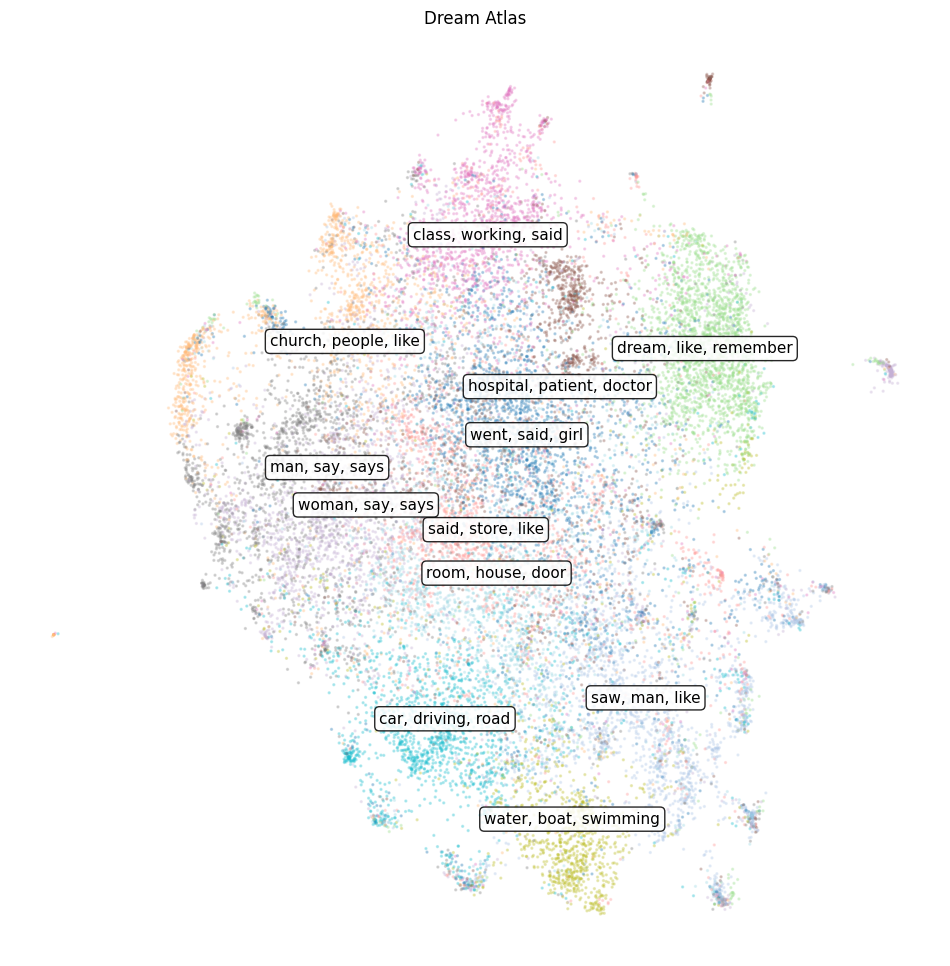

In [85]:
namen = {}
for c in range(12):
    maske = labels2 == c
    mittel = np.asarray(X_clean[maske].mean(axis=0)).ravel()
    namen[c] = ", ".join(terme_clean[np.argsort(-mittel)[:3]])

plt.figure(figsize=(12, 12))
plt.scatter(UV2[:, 0], UV2[:, 1], s=2, alpha=0.25, c=labels2, cmap="tab20")

for c in range(12):
    maske = labels2 == c
    x, y = np.median(UV2[maske, 0]), np.median(UV2[maske, 1])
    plt.text(x, y, namen[c], fontsize=11, ha="center",
             bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.85))

plt.axis("off")
plt.title("Dream Atlas")
plt.show()

In [86]:
anteil = (pd.crosstab(df_clean["series"], labels2 == 3, normalize="index")[True]
            .sort_values(ascending=False))
gesamt = df_clean["series"].value_counts()

print(pd.DataFrame({"anteil": anteil, "gesamt": gesamt}).head(12).to_string())

                      anteil  gesamt
series                              
alta                0.002370     422
angie               0.291667      48
arlie               0.042453     212
b                   0.036907    2845
b-baseline          0.036000     250
b2                  0.035305    1133
bay_area_girls_456  0.192308     234
bay_area_girls_789  0.175325     154
bea1                0.228700     223
bea2                0.539683      63
blind-f             0.218487     238
blind-m             0.349650     143


In [87]:
tab = pd.DataFrame({"anteil": anteil, "gesamt": gesamt})
print(tab[tab["gesamt"] >= 100].sort_values("anteil", ascending=False).head(12).to_string())

                   anteil  gesamt
series                           
jasmine3         0.647287     258
jasmine2         0.498141     269
miami-lab        0.463504     274
melvin           0.414062     128
peru-f           0.351706     381
blind-m          0.349650     143
melora           0.322275     211
midwest_teens-f  0.270270     111
miami-home       0.269006     171
peru-m           0.260417     384
hall_female      0.230543     681
bea1             0.228700     223


In [88]:
import numpy as np, json

df_clean.to_parquet("dreams.parquet")
np.save("embeddings.npy", E2.astype("float32"))
np.save("atlas_xy.npy", UV2.astype("float32"))
np.save("clusters.npy", labels2)
json.dump({str(c): namen[c] for c in namen}, open("cluster_names.json", "w"))

print("gespeichert")

gespeichert


In [89]:
!pip install -q gradio plotly


In [90]:
import app
app.demo.launch(share=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

22096 Traeume geladen, 384 Dimensionen


/content/app.py:112: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="dream-atlas", theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://443f4eb87a26787ebb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [93]:
import importlib, app
importlib.reload(app)
print(app.KARTE_PUNKTE)      # muss 7000 ausgeben
app.demo.launch(share=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

22096 Traeume geladen, 384 Dimensionen
7000


/content/app.py:155: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://977b33d6fe0f8f2f9d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [94]:
namen_schoen = {
    0:  "Schule & Alltag",
    1:  "Begegnungen",
    2:  "Kirche & Bühne",
    3:  "mündlich erzählte Träume",
    4:  "Geschäfte & Einkaufen",
    5:  "Gespräche",
    6:  "Krankenhaus",
    7:  "Arbeit & Unterricht",
    8:  "Nähe & Gefühle",
    9:  "Wasser",
    10: "Autos & Straßen",
    11: "Häuser & Räume",
}

json.dump({str(c): n for c, n in namen_schoen.items()},
          open("cluster_names.json", "w"))

In [95]:
for i in df_clean.index[labels2 == 1][:5]:
    print(df_clean["dreams"].iloc[i][:150], "\n---")

I was outside my house, at dusk, with Steve and Matt. I was wearing my boots. Also, Bill Murray was with us. we were running up and down the side of m 
---
I am in hell. It is a frozen, barren wasteland filled with screaming souls. The icy wind cut through my skin like daggers. Satan appears as a huge bla 
---
I dreamt Mr. N had a gun, and was holding all the 6th grade teachers (but Mr. P) and a bunch of students hostage in his classroom. I think Mr. M owed  
---
I drove my car to school, and parked it behind the music building, right up next to the fence. I had something in my hand which my inner voice kept re 
---
I dreamed that I was in some kind of medieval landscape, laying in the base of a cylindrical tower with my enemy. Guess it was a dungeon. We conversed 
---


In [96]:
for i in df_clean.index[labels2 == 1][:15]:
    print(df_clean["dreams"].iloc[i][:200], "\n---")

I was outside my house, at dusk, with Steve and Matt. I was wearing my boots. Also, Bill Murray was with us. we were running up and down the side of my road on that rise, like I used to do, when all o 
---
I am in hell. It is a frozen, barren wasteland filled with screaming souls. The icy wind cut through my skin like daggers. Satan appears as a huge black cloud that demons flew around, changing from tw 
---
I dreamt Mr. N had a gun, and was holding all the 6th grade teachers (but Mr. P) and a bunch of students hostage in his classroom. I think Mr. M owed money to Mr. N, so he got the hostages. He was get 
---
I drove my car to school, and parked it behind the music building, right up next to the fence. I had something in my hand which my inner voice kept referring to as a Blitz, and I didn't want it. It lo 
---
I dreamed that I was in some kind of medieval landscape, laying in the base of a cylindrical tower with my enemy. Guess it was a dungeon. We conversed for a while, very politel

In [97]:
gefahr = (r"\b(gun|guns|knife|sword|bomb|shoot|shot|killed|kill|attack|"
          r"chasing|chased|scared|afraid|monster|snake|snakes|blood|"
          r"dead|death|fight|fighting)\b")

maske = labels2 == 1
im_cluster = df_clean.loc[maske, "dreams"].str.contains(gefahr, case=False).mean()
im_korpus  = df_clean["dreams"].str.contains(gefahr, case=False).mean()

print(f"Cluster 1: {im_cluster:.1%}   Korpus: {im_korpus:.1%}")

/tmp/ipykernel_402/4159163329.py:6: UserWarning:

This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.

/tmp/ipykernel_402/4159163329.py:7: UserWarning:

This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.



Cluster 1: 46.8%   Korpus: 19.3%


In [98]:
namen_schoen[1] = "Bedrohung & Phantastik"
json.dump({str(c): n for c, n in namen_schoen.items()},
          open("cluster_names.json", "w"))

import app, importlib
importlib.reload(app)
print(app.KARTE_PUNKTE)
app.demo.launch(share=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

22096 Traeume geladen, 384 Dimensionen


/content/app.py:155: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



7000
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c994e706304c944826.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
